<a href="https://colab.research.google.com/github/davide-ario/BNN/blob/main/BNN_returns_to_education.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Is the return to schooling constant? A Bayesian neural network view

The Mincer equation, $\log w = \alpha + \beta\,\text{educ} + \gamma_1 \text{exp} + \gamma_2 \text{exp}^2 + \dots$,
assumes that every additional year of schooling raises wages by the same
percentage $\beta$. Two alternatives are plausible:

* **diminishing returns**: each extra year is worth less than the previous one;
* **sheepskin effects**: the payoff comes in steps, when a degree
  (high school, college) is completed.

Here we let a Bayesian neural network (BNN) learn the wage profile from the
data, without imposing any functional form, and read off the **marginal
return to each year of schooling** with credible intervals. We compare it
with the Mincer equation and with an OLS regression that has one dummy per
education level.

**Data**: March 2005 Current Population Survey, as distributed with Stock &
Watson's *Introduction to Econometrics* (`AER::CPSSW8`). It covers 61,395
full-time workers aged 21–64, with average hourly earnings in 2004, years of
education, age, gender and region.

## Setup

In [1]:
import sys

if "google.colab" in sys.modules:
    !pip install -q "pymc>=6.4" "arviz>=1.0"
    !wget -q https://raw.githubusercontent.com/davide-ario/BNN/main/bnn_models.py

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import statsmodels.formula.api as smf
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

import bnn_models as bm

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
SEED = 0
print(f"PyMC v{pm.__version__}")

PyMC v6.4.0


## 1. Data

In [3]:
URL = ("https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/"
       "master/csv/AER/CPSSW8.csv")
df = pd.read_csv(URL, index_col=0)
df["log_wage"] = np.log(df["earnings"])
df["female"] = (df["gender"] == "female").astype(float)
df.head()

,earnings,gender,age,region,education,log_wage,female
rownames,,,,,,,
1,20.673077,male,31,South,14,3.028832,0.0
2,24.278847,male,50,South,12,3.189605,0.0
3,10.149572,male,36,South,12,2.317432,0.0
4,8.894231,female,33,South,10,2.185403,1.0
5,6.410256,female,56,South,10,1.857899,1.0


Education is not recorded in years. It is derived from the highest degree
completed: 12 = high-school diploma, 13 = some college, 14 = associate
degree, 16 = bachelor's, 18 = master's, 19 = professional degree,
20 = doctorate. Values such as 15 or 17 never occur. This matters for
interpretation: above 12 years, a "year of schooling" in these data is really
a step to the next degree.

In [4]:
levels = np.sort(df["education"].unique())
summary = df.groupby("education").agg(n=("log_wage", "size"),
                                      mean_log_wage=("log_wage", "mean"))
summary["raw step per year"] = (summary["mean_log_wage"].diff()
                                / np.diff(levels, prepend=np.nan))
summary.round(3)

,n,mean_log_wage,raw step per year
education,,,
6,791,2.238,NaN
8,703,2.310,0.036
9,801,2.296,-0.014
10,878,2.377,0.081
11,1189,2.363,-0.014
12,19989,2.595,0.231
13,11641,2.725,0.131
14,6719,2.805,0.079
16,12777,3.008,0.102


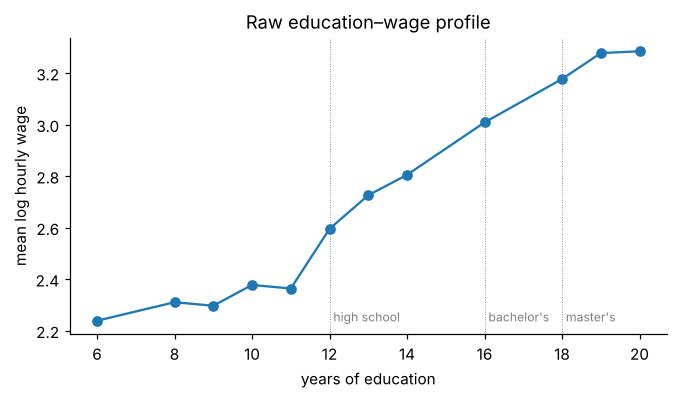

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(summary.index, summary["mean_log_wage"], "o-")
ax.set(xlabel="years of education", ylabel="mean log hourly wage",
       title="Raw education–wage profile")
for e, lab in [(12, "high school"), (16, "bachelor's"), (18, "master's")]:
    ax.axvline(e, color="grey", lw=0.6, ls=":")
    ax.text(e + 0.1, ax.get_ylim()[0] + 0.05, lab, fontsize=8, color="grey")
plt.show()

We hold out 20% of the sample to compare models out of sample.

In [6]:
train, test = train_test_split(df, test_size=0.2, random_state=SEED)
print(f"train: {len(train):,}   test: {len(test):,}")

train: 49,116   test: 12,279


## 2. Benchmarks: OLS

1. **Mincer**: a single return to schooling, a quadratic in age and
   gender and region dummies.
2. **Education dummies**: one dummy per education level, with the same
   controls. This places no restriction on the shape of the education
   profile, but keeps every effect additive: the return to a degree is the
   same for men and women, young and old.

In [7]:
controls = "age + I(age**2) + female + C(region)"
mincer = smf.ols(f"log_wage ~ education + {controls}", train).fit(cov_type="HC1")
dummies = smf.ols(f"log_wage ~ C(education) + {controls}", train).fit(cov_type="HC1")

b, se = mincer.params["education"], mincer.bse["education"]
print(f"Mincer return to schooling: {b:.4f} (s.e. {se:.4f}), "
      f"i.e. {100 * (np.exp(b) - 1):.1f}% per year")

Mincer return to schooling: 0.0926 (s.e. 0.0009), i.e. 9.7% per year


From the dummy model we compute the marginal return *per year* between two
consecutive education levels, $(\delta_{e_k} - \delta_{e_{k-1}}) / (e_k - e_{k-1})$,
with its 90% confidence interval.

In [8]:
def dummy_steps(fit):
    """Per-year log-wage step between consecutive education levels."""
    names = ["Intercept"] + [f"C(education)[T.{e}]" for e in levels[1:]]
    rows = []
    for k in range(1, len(levels)):
        w = pd.Series(0.0, index=fit.params.index)
        w[names[k]] = 1.0
        if k > 1:
            w[names[k - 1]] = -1.0
        w /= levels[k] - levels[k - 1]
        est = float(w @ fit.params)
        sd = float(np.sqrt(w @ fit.cov_params() @ w))
        rows.append((levels[k], est, est - 1.645 * sd, est + 1.645 * sd))
    return pd.DataFrame(rows, columns=["education", "step", "lo", "hi"])


ols_steps = dummy_steps(dummies)
ols_steps.round(3)

,education,step,lo,hi
0,8,0.041,0.020,0.062
1,9,0.008,-0.035,0.052
2,10,0.073,0.033,0.113
3,11,0.019,-0.019,0.056
4,12,0.203,0.177,0.230
5,13,0.156,0.146,0.166
6,14,0.067,0.054,0.080
7,16,0.101,0.094,0.107
8,18,0.070,0.063,0.078
9,19,0.082,0.042,0.121


## 3. Bayesian neural network

The BNN takes years of education, age, gender and region as inputs. It has
three ReLU hidden layers of 30 units and is fitted by mini-batch ADVI. With
49,000 training observations, each iteration uses a random batch of 100, so
one pass over the data takes about 490 iterations. Inputs and output are
standardised. The network can create any interaction it needs, for example
a return to college that differs by gender or age.

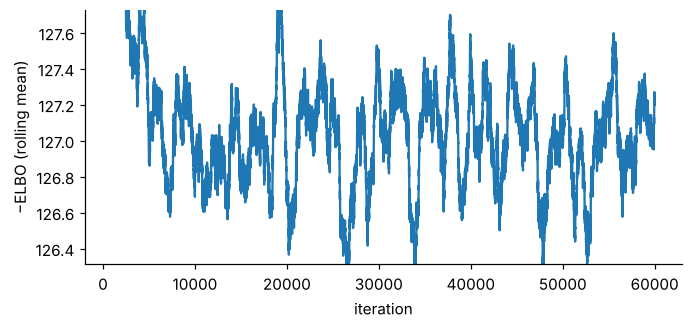

In [9]:
REGIONS = ["Midwest", "South", "West"]  # Northeast is the reference


def design(d):
    """Raw regressor matrix: education, age, female, region dummies."""
    X = d[["education", "age", "female"]].to_numpy(float)
    R = np.column_stack([(d["region"] == r).to_numpy(float) for r in REGIONS])
    return np.hstack([X, R])


X_train = design(train)
x_mean, x_sd = X_train.mean(0), X_train.std(0)
y_mean, y_sd = train["log_wage"].mean(), train["log_wage"].std()


def scale(X):
    return (X - x_mean) / x_sd


idata_bnn, hist_bnn = bm.fit_advi(
    bm.build_bnn, scale(X_train), (train["log_wage"] - y_mean) / y_sd,
    n_iter=60_000, batch_size=100, seed=SEED)

fig, ax = plt.subplots(figsize=(7, 3))
loss = pd.Series(hist_bnn).rolling(1000).mean()
ax.plot(loss)
ax.set(xlabel="iteration", ylabel="−ELBO (rolling mean)",
       ylim=np.nanpercentile(loss[3000:], [0.5, 99.5]))
plt.show()

### Out-of-sample fit

Log wages are noisy at the individual level (we observe no ability,
occupation or industry), so no model explains much more than a quarter of
the variance. The question is whether the BNN does at least as well as the
regressions while imposing less structure.

In [10]:
mu_test = bm.predict_mu(bm.build_bnn, idata_bnn, scale(design(test)))
fit_table = pd.Series({
    "OLS Mincer": r2_score(test["log_wage"], mincer.predict(test)),
    "OLS education dummies": r2_score(test["log_wage"], dummies.predict(test)),
    "BNN": r2_score(test["log_wage"], mu_test.mean(0) * y_sd + y_mean),
}, name="test R²").round(4)
fit_table.to_frame()

,test R²
OLS Mincer,0.2578
OLS education dummies,0.2612
BNN,0.2638


## 4. Marginal return to each year of schooling

For a reference sample of workers, we set everyone's education to each level
$e_k$ in turn, keep all other characteristics at their observed values, and
average the predicted log wage. This gives the education–wage profile
$\mathrm{PD}(e_k)$ for every posterior draw. The marginal return per year is

$$r_k = \frac{\mathrm{PD}(e_k) - \mathrm{PD}(e_{k-1})}{e_k - e_{k-1}},$$

in log points; multiplied by 100 it is approximately the percentage wage
gain from one more year.

In [11]:
reference = test.sample(2000, random_state=SEED)


def bnn_steps(ref, builder=bm.build_bnn, idata=None):
    """Posterior draws of the per-year return between consecutive levels."""
    idata = idata_bnn if idata is None else idata
    stacked = pd.concat([ref.assign(education=e) for e in levels])
    mu = bm.predict_mu(builder, idata, scale(design(stacked)))
    profile = mu.reshape(mu.shape[0], len(levels), len(ref)).mean(axis=2) * y_sd
    return np.diff(profile, axis=1) / np.diff(levels)


steps_all = bnn_steps(reference)


def summarise(draws):
    lo, med, hi = np.percentile(draws, [5, 50, 95], axis=0)
    return pd.DataFrame({"education": levels[1:], "step": med, "lo": lo, "hi": hi})


bnn_table = summarise(steps_all)
pd.concat({"BNN": bnn_table.set_index("education"),
           "OLS dummies": ols_steps.set_index("education")}, axis=1).round(3)

BNN               OLS dummies              
            step     lo     hi        step     lo     hi
education                                               
8          0.052  0.031  0.070       0.041  0.020  0.062
9          0.057  0.041  0.070       0.008 -0.035  0.052
10         0.081  0.067  0.094       0.073  0.033  0.113
11         0.117  0.105  0.128       0.019 -0.019  0.056
12         0.135  0.129  0.142       0.203  0.177  0.230
13         0.135  0.129  0.143       0.156  0.146  0.166
14         0.102  0.095  0.111       0.067  0.054  0.080
16         0.085  0.079  0.095       0.101  0.094  0.107
18         0.060  0.050  0.075       0.070  0.063  0.078
19         0.053  0.040  0.073       0.082  0.042  0.121
20         0.048  0.033  0.071      -0.040 -0.092  0.011

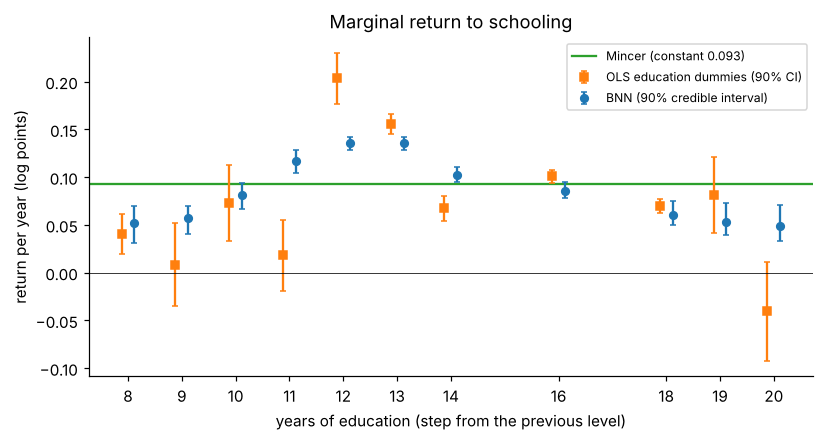

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.axhline(b, color="C2", lw=1.5, label=f"Mincer (constant {b:.3f})")
ax.errorbar(ols_steps["education"] - 0.12, ols_steps["step"],
            yerr=[ols_steps["step"] - ols_steps["lo"], ols_steps["hi"] - ols_steps["step"]],
            fmt="s", color="C1", ms=5, capsize=2, label="OLS education dummies (90% CI)")
ax.errorbar(bnn_table["education"] + 0.12, bnn_table["step"],
            yerr=[bnn_table["step"] - bnn_table["lo"], bnn_table["hi"] - bnn_table["step"]],
            fmt="o", color="C0", ms=5, capsize=2, label="BNN (90% credible interval)")
ax.axhline(0, color="k", lw=0.5)
ax.set(xlabel="years of education (step from the previous level)",
       ylabel="return per year (log points)", xticks=levels[1:],
       title="Marginal return to schooling")
ax.legend(fontsize=8)
plt.show()

## 5. Does the return differ by gender and age?

The OLS models impose the same education profile on everybody. The BNN
does not, so we can compute the same marginal returns separately for
subgroups of the reference sample.

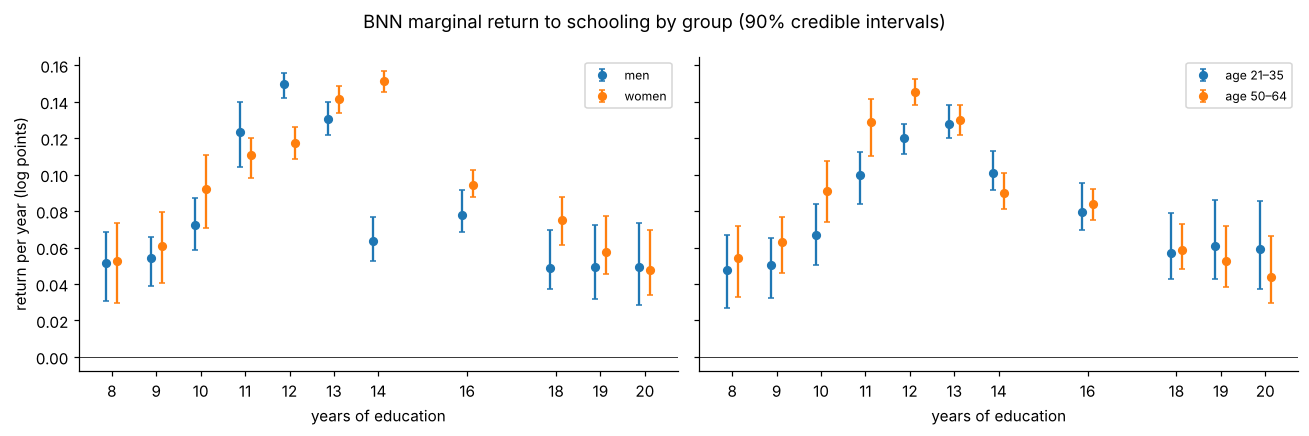

In [13]:
groups = {
    "men": reference[reference["female"] == 0],
    "women": reference[reference["female"] == 1],
    "age 21–35": reference[reference["age"] <= 35],
    "age 50–64": reference[reference["age"] >= 50],
}
group_steps = {name: summarise(bnn_steps(g)) for name, g in groups.items()}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, pair in zip(axes, [("men", "women"), ("age 21–35", "age 50–64")]):
    for i, name in enumerate(pair):
        t = group_steps[name]
        ax.errorbar(t["education"] + (i - 0.5) * 0.25, t["step"],
                    yerr=[t["step"] - t["lo"], t["hi"] - t["step"]],
                    fmt="o", ms=5, capsize=2, label=name)
    ax.axhline(0, color="k", lw=0.5)
    ax.set(xlabel="years of education", xticks=levels[1:])
    ax.legend(fontsize=8)
axes[0].set_ylabel("return per year (log points)")
fig.suptitle("BNN marginal return to schooling by group (90% credible intervals)")
plt.tight_layout()
plt.show()

A single number summarises each gap: the average return per year between
12 and 16 years of schooling (high school to bachelor's), with the
posterior probability that it is higher in the first group.

In [14]:
def college_return(ref, builder=bm.build_bnn, idata=None):
    """Posterior draws of the average return per year from 12 to 16 years."""
    idata = idata_bnn if idata is None else idata
    stacked = pd.concat([ref.assign(education=e) for e in (12, 16)])
    mu = bm.predict_mu(builder, idata, scale(design(stacked)))
    pdp = mu.reshape(mu.shape[0], 2, len(ref)).mean(axis=2) * y_sd
    return (pdp[:, 1] - pdp[:, 0]) / 4


rows = []
for a, b_ in [("women", "men"), ("age 21–35", "age 50–64")]:
    ra, rb = college_return(groups[a]), college_return(groups[b_])
    rows.append({"comparison": f"{a} vs {b_}",
                 f"return, first group": ra.mean(), "return, second group": rb.mean(),
                 "difference": (ra - rb).mean(),
                 "90% interval": f"[{np.percentile(ra - rb, 5):.3f}, {np.percentile(ra - rb, 95):.3f}]",
                 "P(first > second)": (ra > rb).mean()})
pd.DataFrame(rows).set_index("comparison").round(3)

,"return, first group","return, second group",difference,90% interval,P(first > second)
comparison,,,,,
women vs men,0.121,0.088,0.033,"[0.024, 0.040]",1.000
age 21–35 vs age 50–64,0.098,0.097,0.001,"[-0.009, 0.011]",0.514


## 6. One coefficient, flexible controls: partially linear BNN

If a single summary number is still wanted, the partially linear BNN keeps
education linear but lets a network model age, gender and region with all
their interactions:

$$\log w = \alpha + \beta\,\text{educ} + f(\text{age}, \text{female}, \text{region}) + \varepsilon$$

Comparing $\hat\beta$ with the Mincer coefficient shows how much the
Mincer estimate depends on its quadratic-in-age, additive specification of
the controls.

In [15]:
idata_pl, _ = bm.fit_advi(
    bm.build_partially_linear_bnn, scale(X_train),
    (train["log_wage"] - y_mean) / y_sd,
    n_iter=60_000, batch_size=100, seed=SEED, linear_cols=(0,))
beta_pl = idata_pl.posterior["beta"].values.reshape(-1) * y_sd / x_sd[0]

pd.DataFrame({
    "estimate": [b, beta_pl.mean()],
    "s.e. / posterior sd": [se, beta_pl.std()],
    "5%": [b - 1.645 * se, np.percentile(beta_pl, 5)],
    "95%": [b + 1.645 * se, np.percentile(beta_pl, 95)],
}, index=["OLS Mincer", "Partially linear BNN"]).round(4)

,estimate,s.e. / posterior sd,5%,95%
OLS Mincer,0.0926,0.0009,0.0911,0.0940
Partially linear BNN,0.0953,0.0009,0.0938,0.0968


## 7. Robustness: nested BNN and run-to-run variation

Two checks:

1. **Does the nested BNN do better?** It routes each input to a ReLU or a
   bounded tanh sub-network (see `Nested-BayesianNN.ipynb`). On simulated
   data with a strong cubic term it halved the error of the standard BNN.
2. **How reliable are the credible intervals?** Mean-field ADVI tends to
   understate posterior uncertainty, and the variational fit also depends on
   the random seed. We refit both networks with five seeds. Pooling the
   draws from all runs gives an interval that also reflects run-to-run
   variation (a simple ensemble of variational posteriors).

This cell fits nine more networks and takes several minutes.

In [16]:
SEEDS = [0, 1, 2, 3, 4]
BUILDERS = {"BNN": bm.build_bnn, "Nested BNN": bm.build_nested_bnn}
ys_train = (train["log_wage"] - y_mean) / y_sd

runs = {name: {} for name in BUILDERS}
runs["BNN"][SEED] = idata_bnn  # already fitted in section 3
for name, builder in BUILDERS.items():
    for s in SEEDS:
        if s not in runs[name]:
            runs[name][s], _ = bm.fit_advi(builder, scale(X_train), ys_train,
                                           n_iter=60_000, batch_size=100, seed=s)

X_test_s = scale(design(test))
r2 = pd.DataFrame({
    name: {s: r2_score(test["log_wage"],
                       bm.predict_mu(BUILDERS[name], idata, X_test_s).mean(0) * y_sd + y_mean)
           for s, idata in runs[name].items()}
    for name in BUILDERS})
r2.index.name = "seed"
r2.loc["mean"] = r2.mean()
r2.loc["sd"] = r2.iloc[:-1].std()
r2.round(4)

,BNN,Nested BNN
seed,,
0,0.2638,0.2634
1,0.2612,0.2613
2,0.2623,0.2590
3,0.2595,0.2654
4,0.2577,0.2639
mean,0.2609,0.2626
sd,0.0024,0.0025


**Test R².** The two networks fit equally well. The difference between
them is smaller than the difference between two runs of the same model.
With only six inputs, and the large effects coming from smooth functions of
education and age, the nested architecture has little extra to exploit.

**Routing.** The posterior mean of `model_sel` (0 = ReLU network,
1 = tanh network) is stable across seeds. Education and age, the large
continuous effects, go mostly to the unbounded ReLU network; the region
dummies, small level shifts, go to the bounded tanh network.

In [17]:
sel = pd.DataFrame(
    {s: idata.posterior["model_sel"].mean(("chain", "draw")).values
     for s, idata in runs["Nested BNN"].items()},
    index=["education", "age", "female", "Midwest", "South", "West"]).T
sel.index.name = "seed"
sel.round(2)

,education,age,female,Midwest,South,West
seed,,,,,,
0,0.34,0.14,0.54,0.89,0.86,0.96
1,0.35,0.11,0.57,0.90,0.87,0.95
2,0.23,0.13,0.46,0.86,0.85,0.94
3,0.21,0.10,0.74,0.90,0.87,0.94
4,0.40,0.22,0.63,0.90,0.89,0.95


BNN, average width of the 90% interval: one run 0.025, five runs pooled 0.045 (1.8x)


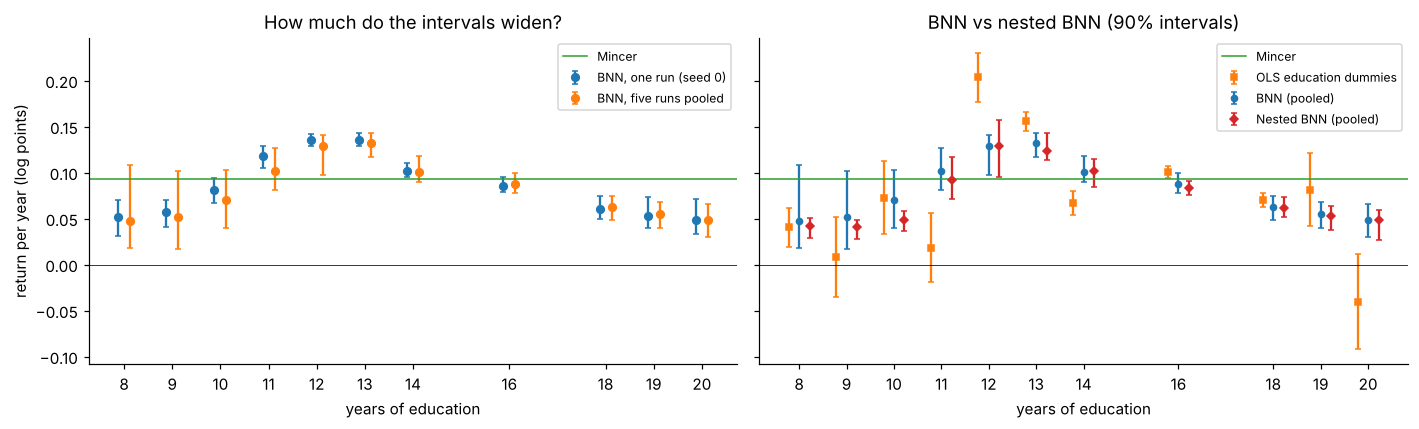

In [18]:
steps = {name: {s: bnn_steps(reference, BUILDERS[name], idata)
                for s, idata in runs[name].items()}
         for name in BUILDERS}
pooled = {name: summarise(np.concatenate(list(d.values()))) for name, d in steps.items()}
single = summarise(steps["BNN"][SEED])

width_single = (single["hi"] - single["lo"]).mean()
width_pooled = (pooled["BNN"]["hi"] - pooled["BNN"]["lo"]).mean()
print(f"BNN, average width of the 90% interval: one run {width_single:.3f}, "
      f"five runs pooled {width_pooled:.3f} ({width_pooled / width_single:.1f}x)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for i, (label, t) in enumerate([("BNN, one run (seed 0)", single),
                                ("BNN, five runs pooled", pooled["BNN"])]):
    axes[0].errorbar(t["education"] + (i - 0.5) * 0.25, t["step"],
                     yerr=[t["step"] - t["lo"], t["hi"] - t["step"]],
                     fmt="o", ms=5, capsize=2, label=label)
axes[0].set_title("How much do the intervals widen?")
for i, (label, t) in enumerate([("OLS education dummies", ols_steps),
                                ("BNN (pooled)", pooled["BNN"]),
                                ("Nested BNN (pooled)", pooled["Nested BNN"])]):
    axes[1].errorbar(t["education"] + (i - 1) * 0.22, t["step"],
                     yerr=[t["step"] - t["lo"], t["hi"] - t["step"]],
                     fmt="soD"[i], ms=4, capsize=2, color=f"C{(1, 0, 3)[i]}", label=label)
axes[1].set_title("BNN vs nested BNN (90% intervals)")
for ax in axes:
    ax.axhline(b, color="C2", lw=1, label="Mincer")
    ax.axhline(0, color="k", lw=0.5)
    ax.set(xlabel="years of education", xticks=levels[1:])
    ax.legend(fontsize=8)
axes[0].set_ylabel("return per year (log points)")
plt.tight_layout()
plt.show()

Finally, does the gender gap in the return to college survive across runs
and architectures?

In [19]:
rows = []
for name, builder in BUILDERS.items():
    diff = np.concatenate([college_return(groups["women"], builder, idata)
                           - college_return(groups["men"], builder, idata)
                           for idata in runs[name].values()])
    rows.append({"model (5 runs pooled)": name, "women − men": diff.mean(),
                 "5%": np.percentile(diff, 5), "95%": np.percentile(diff, 95),
                 "P(women > men)": (diff > 0).mean()})
pd.DataFrame(rows).set_index("model (5 runs pooled)").round(3)

,women − men,5%,95%,P(women > men)
model (5 runs pooled),,,,
BNN,0.029,0.018,0.041,0.998
Nested BNN,0.026,0.018,0.033,1.000


## 8. Takeaways

* **The return is not constant.** Both flexible models reject the Mincer
  assumption. Returns peak around the end of high school and the first year
  of college (13–20% per year in the OLS dummies, about 13.5% in the BNN).
  Beyond a bachelor's degree they fall to about 5–8% per year, below the
  Mincer estimate of 9.3%.
* **Steps or diminishing returns? Both, depending on the range.**
  - Below 12 years, the education dummies show a clear *sheepskin* effect:
    years 9 and 11 add almost nothing, while the year that completes the
    diploma adds about 20 log points.
  - Above 13 years, returns decline with each further degree, as you would
    expect with diminishing returns.
* **What the BNN misses.** Education enters the network as a continuous
  number, so it fits a smooth curve: it spreads the diploma jump over years
  11–13 and reports overly narrow intervals there (mean-field ADVI is known
  to understate uncertainty). Where data are plentiful (12 years and above)
  it agrees closely with the dummies. It still has the best out-of-sample
  fit, but the margin over the dummy regression is small (R² 0.264 against
  0.261).
* **Heterogeneity is where the BNN adds most.** Without being told to look
  for interactions, it finds that college pays more for women: about 12.1%
  per year between 12 and 16 years of schooling, against 8.8% for men (the
  posterior probability that women's return is higher is about 1). The gap
  comes mainly from the associate-degree years. By contrast, returns are
  almost identical for younger and older workers. An additive OLS model
  cannot show either result unless the analyst specifies the interaction.
* **The average is robust.** With flexible controls, the partially linear
  BNN gives an average return of 9.5% (log points) per year, against 9.3%
  for Mincer. The quadratic-in-age specification of the controls is not
  what drives the Mincer estimate.
* **The nested BNN is no better here.** Across five seeds its test R² is
  0.263 ± 0.003, against 0.261 ± 0.002 for the BNN, a difference well
  within run-to-run noise. It routes education and age to the ReLU network
  and the region dummies to the bounded tanh network, consistently across
  seeds, and yields the same education profile.
* **Treat single-run intervals with caution.** Pooling five runs widens
  the BNN's 90% intervals by a factor of 1.8 on average. The shape of the
  profile and the gender gap (2.9 points [1.8, 4.1] in the pooled BNN,
  2.6 in the nested BNN) survive this check.
* **Caveat.** These are conditional associations, not causal effects. Ability
  bias and selection into education are not addressed here. Card (1995)
  tackles them with college proximity as an instrument.